In [1]:
#from bai_utils import *
from tbp_utils_2 import *
from experiments import sim_perf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from collections import defaultdict
from sklearn.preprocessing import normalize
import ipdb

In [3]:
def gen_data_bench(N=100, d=2, scale=1, sigma=1):

    theta = (2*np.random.rand(d)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,d).reshape(N, d)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    f = x @ theta
    y = np.random.normal(loc=f, scale=sigma)
    return x, y, theta

In [4]:
x, y, theta = gen_data_bench(scale=10)
deltas = [0.1,0.05,0.01,0.001]
T_max = 1000
N = 10
d = 2
#x = np.eye(d)
rho = 0
alpha = 0.1
#x = np.concatenate([x, (rho-0.2)*(np.cos(alpha) * x[0:1] + np.sin(alpha) * x[1:2])])
#x = np.concatenate([x, (x[0:1]*(1/2+0.05) + x[1:2]*(1/2-0.05) )])#+ x[2:3]*(1/3))])
#theta = x[0]
max(x @ theta)

9.35364660944599

In [5]:
deltas = [0.1,0.05,0.01,0.001]
T_max = 1000
N = 10
d = 2
x = np.eye(d)
rho = 0.5
alpha = 0.1
x = np.concatenate([x, (rho-0.2)*(np.cos(alpha) * x[0:1] + np.sin(alpha) * x[1:2])])
#x = np.concatenate([x, (x[0:1]*(1/2+0.05) + x[1:2]*(1/2-0.05) )])#+ x[2:3]*(1/3))])
theta = x[0]
x @ theta

array([1.        , 0.        , 0.29850125])

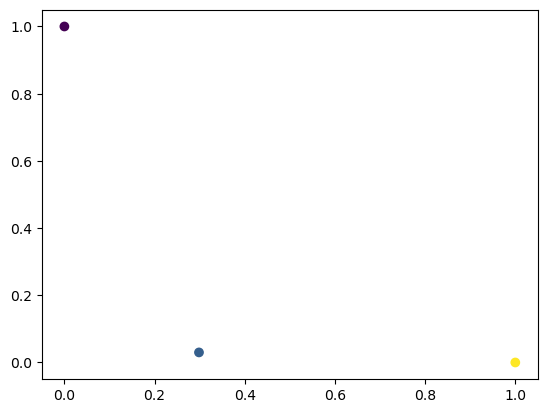

In [6]:
plt.scatter(x[:,0], x[:,1], c=x @ theta)

In [7]:
performance, tau = sim_perf(lazy_TS, x, theta, rho, deltas, T_max, N, epsilon=0)

100%|█████████████████████████████████████████████| 4/4 [01:58<00:00, 29.72s/it]


In [8]:
pd.DataFrame(performance).mean()

0.100    0.0
0.050    0.0
0.010    0.0
0.001    0.0
dtype: float64

In [9]:
pd.DataFrame(tau).mean(), pd.DataFrame(tau).std()

(0.100    252.5
 0.050    264.2
 0.010    292.6
 0.001    335.2
 dtype: float64,
 0.100    66.511904
 0.050    57.944034
 0.010    47.190395
 0.001    56.041255
 dtype: float64)

In [19]:
performance, tau = sim_perf(LinGapE, x, theta, rho, deltas, T_max, N=100, seed=476, epsilon=0)

100%|█████████████████████████████████████████████| 4/4 [00:17<00:00,  4.31s/it]


In [20]:
pd.DataFrame(performance).mean()

0.100    0.0
0.050    0.0
0.010    0.0
0.001    0.0
dtype: float64

In [21]:
pd.DataFrame(tau).mean(), pd.DataFrame(tau).std()

(0.100    220.22
 0.050    235.48
 0.010    260.50
 0.001    293.69
 dtype: float64,
 0.100    58.352738
 0.050    61.610946
 0.010    66.530998
 0.001    72.835458
 dtype: float64)

In [17]:
rho = .5
seed = np.random.randint(10)
eta = 0#(1 / np.linspace(1,10,10))[4]
x = x[np.abs(x @ theta - rho) > eta, :]
epsilon = 0#(np.round(np.sort(x @ theta), 1)).std() / 100
opt_desing = optimal_allocation(x, theta, rho, epsilon)
A_lambda = np.multiply((x[:,:,None] @ x[:,None]), opt_desing[0][:,None, None]).sum(0)
m, d = x.shape
prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
              }
prob = linear_discover(**prob_dict)
        
t_prob = deepcopy(prob)
#solver = xy_adaptive(t_prob, rho, epsilon)
#g_arms, perf, tau = solver.run(1000, 1, 0.05)

solver = linear_solver(t_prob, rho, epsilon)
g_arms0, perf0, tau0 = solver.run(1000, 0.05, seed)

solver = lazy_TS(t_prob, rho, epsilon)
g_arms1, perf1, tau1 = solver.run(1000, 0.05, seed)

t_prob = deepcopy(prob)
solver2 = Oracle_linear(t_prob, rho, epsilon, opt_desing[0])
g_arms2, perf2, tau2 = solver2.run(1000, 0.05, seed)

t_prob = deepcopy(prob)
solver3 = G_allocation(t_prob, rho, epsilon)
g_arms3, perf3, tau3 = solver3.run(1000, 0.05, seed)

t_prob = deepcopy(prob)
solver4 = G_allocation_phase(t_prob, rho, epsilon)
g_arms4, perf4, tau4 = solver4.run(1000, 0.05, seed)

t_prob = deepcopy(prob)
solver5 = x_adaptive(t_prob, rho, epsilon)
g_arms5, perf5, tau5 = solver5.run(1000, 1.1, 0.05, seed)

t_prob = deepcopy(prob)
solver6 = LinGapE(t_prob, rho, epsilon)
g_arms6, perf6, tau6 = solver6.run(1000, 0.05, seed)

tau0,tau1,tau2,tau3,tau4,tau5,tau6

(659, 191, 190, 331, 330, 1000, 212)

In [6]:
tau1,tau2,tau3,tau4,tau5,tau6

(308, 673, 424, 440, 1000, 305)

In [7]:
perf0,perf1,perf2,perf3,perf4,perf5,perf6

((0, 0), (0, 0), (0, 0), (0, 0), (0, 0), (1, 2), (0, 0))

In [20]:
perf2, tau2

((0, 0), 4)

In [86]:
mean_list = defaultdict(list)
rho_list = defaultdict(list)
epsilon_list = defaultdict(list)
gap_list = defaultdict(list)
x_list = defaultdict(list)
A_lambda_list = defaultdict(list)

mean_hat_list1 = defaultdict(list)
tau_list1 = defaultdict(list)
succ_list1 = defaultdict(list)
g_arms_list1 = defaultdict(list)
perf_list1 = defaultdict(list)
A_list1 = defaultdict(list)

mean_hat_list2 = defaultdict(list)
tau_list2 = defaultdict(list)
succ_list2 = defaultdict(list)
g_arms_list2 = defaultdict(list)
perf_list2 = defaultdict(list)
A_list2 = defaultdict(list)

mean_hat_list3 = defaultdict(list)
tau_list3 = defaultdict(list)
succ_list3 = defaultdict(list)
g_arms_list3 = defaultdict(list)
perf_list3 = defaultdict(list)
A_list3 = defaultdict(list)

mean_hat_list4 = defaultdict(list)
tau_list4 = defaultdict(list)
succ_list4 = defaultdict(list)
g_arms_list4 = defaultdict(list)
perf_list4 = defaultdict(list)
A_list4 = defaultdict(list)

mean_hat_list5 = defaultdict(list)
tau_list5 = defaultdict(list)
succ_list5 = defaultdict(list)
g_arms_list5 = defaultdict(list)
perf_list5 = defaultdict(list)
A_list5 = defaultdict(list)

mean_hat_list6 = defaultdict(list)
tau_list6 = defaultdict(list)
succ_list6 = defaultdict(list)
g_arms_list6 = defaultdict(list)
perf_list6 = defaultdict(list)
A_list6 = defaultdict(list)

for delta in tqdm([0.1,0.05,0.01,0.001]):
    for i in range(5):
        #x, y, theta = gen_data_bench(100, d=2, scale=20)

        #rho = np.quantile(x @ theta, .50)
        rho = .5
        rho_list[delta].append(rho)
        #x = x[np.abs(x @ theta - rho) > eta, :]

        x_list[delta].append(x)
        epsilon = 0#(np.round(np.sort(x @ theta), 1)).std() / 100
        epsilon_list[delta].append(epsilon)
        opt_desing = optimal_allocation(x, theta, rho, epsilon)
        A_lambda = np.multiply((x[:,:,None] @ x[:,None]), opt_desing[0][:,None, None]).sum(0)
        A_lambda_list[delta].append(A_lambda)
        gap_list[delta].append(np.sort(x @ theta)[-1] - np.sort(x @ theta)[-2])
        mean_list[delta].append(x @ theta)
        m, d = x.shape
        prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
              }

        prob = linear_discover(**prob_dict)
        
        #t_prob = deepcopy(prob)
        #solver = G_allocation(t_prob, rho, epsilon)
        #g_arms, perf, tau = solver.run(1000, delta, i)
        #tau_list1[delta].append(tau)
        #g_arms_list1[delta].append(g_arms)
        #perf_list1[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        #mean_hat_list1[delta].append(x @ solver.theta_hat)
        #A_list1[delta].append(solver.A)

        t_prob = deepcopy(prob)
        solver = lazy_TS(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, delta, i)
        tau_list2[delta].append(tau)
        g_arms_list2[delta].append(g_arms)
        perf_list2[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list2[delta].append(x @ solver.theta_hat)
        A_list2[delta].append(solver.A)
        
        
        t_prob = deepcopy(prob)
        solver = Oracle_linear(t_prob, rho, epsilon, opt_desing[0])
        g_arms, perf, tau = solver.run(1000, delta, i)
        tau_list3[delta].append(tau)
        g_arms_list3[delta].append(g_arms)
        perf_list3[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list3[delta].append(x @ solver.theta_hat)
        A_list3[delta].append(solver.A)
        
        
        t_prob = deepcopy(prob)
        solver = G_allocation_phase(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, delta, i)
        tau_list4[delta].append(tau)
        g_arms_list4[delta].append(g_arms)
        perf_list4[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list4[delta].append(x @ solver.theta_hat)
        A_list4[delta].append(solver.A)
        
        #t_prob = deepcopy(prob)
        #solver = x_adaptive(t_prob, rho, epsilon)
        #g_arms, perf, tau = solver.run(1000, 1.1, delta,i)
        #tau_list5[delta].append(tau)
        #g_arms_list5[delta].append(g_arms)
        #perf_list5[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        #mean_hat_list5[delta].append(x @ solver.theta_hat)
        #A_list5[delta].append(solver.A)
        
        t_prob = deepcopy(prob)
        solver = LinGapE(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, delta,i)
        tau_list6[delta].append(tau)
        g_arms_list6[delta].append(g_arms)
        perf_list6[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list6[delta].append(x @ solver.theta_hat)
        A_list6[delta].append(solver.A)

100%|█████████████████████████████████████████████| 4/4 [01:17<00:00, 19.30s/it]


In [87]:
pd.DataFrame(perf_list1).mean()

Series([], dtype: float64)

In [91]:
pd.DataFrame(perf_list2).mean()

0.100    0.0
0.050    0.0
0.010    0.0
0.001    0.0
dtype: float64

In [92]:
pd.DataFrame(perf_list3).mean()

0.100    0.0
0.050    0.0
0.010    0.0
0.001    0.0
dtype: float64

In [93]:
pd.DataFrame(perf_list4).mean()

0.100    0.0
0.050    0.0
0.010    0.0
0.001    0.0
dtype: float64

In [94]:
pd.DataFrame(perf_list5).mean()

Series([], dtype: float64)

In [95]:
pd.DataFrame(perf_list6).mean()

0.100    0.0
0.050    0.0
0.010    0.0
0.001    0.0
dtype: float64

In [96]:
np.nanmean(pd.DataFrame(tau_list1),0), np.nanstd(pd.DataFrame(tau_list1),0)

(array([], dtype=float64), array([], dtype=float64))

In [97]:
np.nanmean(pd.DataFrame(tau_list2),0), np.nanstd(pd.DataFrame(tau_list2),0)

(array([296.6, 302.2, 333. , 426.6]),
 array([ 86.22899744,  90.23391823, 108.4214001 , 116.34362896]))

In [98]:
np.nanmean(pd.DataFrame(tau_list3),0), np.nanstd(pd.DataFrame(tau_list3),0)

(array([316.6, 336.6, 378. , 443.8]),
 array([ 65.30727371,  63.14617962,  78.42703615, 100.39402373]))

In [99]:
np.nanmean(pd.DataFrame(tau_list4),0), np.nanstd(pd.DataFrame(tau_list4),0)

(array([329.4, 345.6, 401.2, 474.2]),
 array([54.02443891, 64.08931268, 55.41263394, 40.96535121]))

In [100]:
#np.nanmean(pd.DataFrame(tau_list5),0), np.nanstd(pd.DataFrame(tau_list5),0)

In [101]:
np.nanmean(pd.DataFrame(tau_list6),0), np.nanstd(pd.DataFrame(tau_list6),0)

(array([267.2, 280.4, 336.6, 402. ]),
 array([103.68876506, 110.0010909 , 110.55604913, 109.77067004]))

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_86918/2639647926.py:2: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  tau_df = pd.concat([#pd.DataFrame(tau_list1)[delta],


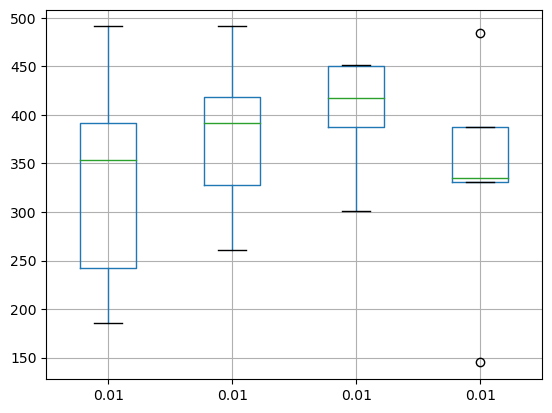

In [102]:
delta = .01
tau_df = pd.concat([#pd.DataFrame(tau_list1)[delta],
                    pd.DataFrame(tau_list2)[delta],
                    pd.DataFrame(tau_list3)[delta],
                    pd.DataFrame(tau_list4)[delta],
                    #pd.DataFrame(tau_list5)[delta],
                    pd.DataFrame(tau_list6)[delta]
                    ],1)
_ = tau_df.boxplot()
plt.show()

In [103]:
x = np.arange(10).reshape(5,2)
x

array([[0, 1],
       [2, 3],
       [4, 5],
       [6, 7],
       [8, 9]])

In [104]:
np.ones((x.shape[1], 1))

array([[1.],
       [1.]])

In [102]:
x@np.ones((x.shape[1], 1))

array([[ 1.],
       [ 5.],
       [ 9.],
       [13.],
       [17.]])

In [105]:
A = np.ones((2,2))

In [106]:
idx = 3
y = x[idx, :, None]
g = ((x@A@y)*(x@A@y)).flatten()
g_idx = np.argmax(g)

In [111]:
y

array([[6],
       [7]])

In [108]:
x@A@y

array([[ 13.],
       [ 65.],
       [117.],
       [169.],
       [221.]])

In [109]:
x@A

array([[ 1.,  1.],
       [ 5.,  5.],
       [ 9.,  9.],
       [13., 13.],
       [17., 17.]])